# Load GBF

Reload a trained GBF PINN and remake figures. Rebuilds the PINN's function and globals from the training script (everything before ~line 1678 "Setup PINN logistics"), using the command-line arguments stored in the checkpoint, then loads the trained weights.

In [1]:
import os, sys, glob
import numpy as np
import pandas as pd
import torch as t
import matplotlib.pyplot as plt

In [5]:
PINN_DIR = "/scratch/wiay/danielk/PINN" #IGR cluster directory
PINN_SCRIPT = os.path.join(PINN_DIR, "PINNGBFWXWS.py") #Either PINNGBFWX.py or PINNGBFWXWS.py (multiple l warm start)
RUN_DIR = os.path.join(PINN_DIR, "GBFWXWSData", "20261121_130556_M0.5_x0.99_WS_T0_g06p4_hf25_128wide", "l4")   #folder holding diagnostics/, results/, comparisons/, network/
FIG_DIR = os.path.join(RUN_DIR, "notebook_figures") #where re-made figures are saved

In [8]:
def argv_from_saved(saved, src):
    #Rebuild the command line from config["arguments"]; skip options the script does not define and path options that would trigger file checks
    #'--key=value' form so values beginning with '-' (or empty strings) can never be read as a new option
    skip = ("init_checkpoint", "reextract_checkpoint", "output_dir")
    argv = []
    for k, v in saved.items():
        if k in skip or k.startswith("output") or v is None or v is False:
            continue
        if f"'--{k}'" not in src and f'"--{k}"' not in src:
            continue
        if v is True:
            argv.append(f"--{k}")
        else:
            argv.append(f"--{k}={v}")
    return argv

def load_run(checkpoint_path, pinn_script, fig_dir):
    ckpt = t.load(checkpoint_path, map_location = "cpu", weights_only = False)
    saved = ckpt["config"]["arguments"]

    #Execute the definitions part of the training script with the saved arguments
    src = open(pinn_script).read()
    cut = src.index("#Setup PINN logistics")
    ns = {"__file__": os.path.abspath(pinn_script), "__name__": "pinn_loaded"}
    old_argv = sys.argv
    sys.argv = [pinn_script] + argv_from_saved(saved, src)
    try:
        exec(compile(src[:cut], pinn_script, "exec"), ns)
    finally:
        sys.argv = old_argv

    #Network shape read from the weights themselves (independent of stale 'hidden_channels' metadata)
    sd = ckpt["model_state_dict"]
    width = sd["input_layer.weight"].shape[0]
    n_hidden = len({k.split(".")[1] for k in sd if k.startswith("hidden_layers.")})
    model = ns["Model"](ns["N_INPUTS"], 4, width, num_hidden_layers = n_hidden).to(device = ns["device"], dtype = ns["DTYPE"])
    model.load_state_dict(sd)
    model.eval()

    #Output folders used by the script's own plotting functions point at fig_dir
    os.makedirs(fig_dir, exist_ok = True)
    for name in ("diagnostic_dir", "envelope_dir", "comparisons_dir", "results_dir", "rar_dir", "final_plots_dir", "clipping_dir"):
        ns[name] = fig_dir
    return model, ns, ckpt

def load_csvs(run_dir):
    return {"report": pd.read_csv(os.path.join(run_dir, "comparisons", "extraction_report.csv")),
            "query": pd.read_csv(os.path.join(run_dir, "results", "PINN_query_frequencies.csv")),
            "loss": pd.read_csv(os.path.join(run_dir, "diagnostics", "loss_history.csv"))}

In [9]:
#Load run
model, P, ckpt = load_run(os.path.join(RUN_DIR, "network", "trained_model.pth"), PINN_SCRIPT, FIG_DIR)
D = load_csvs(RUN_DIR)

mass, mode, x_max = P["mass"], P["mode"], P["x_max"]
print(f"l = {mode}, M = {mass}, x_max = {x_max}, omega in [{P['omega_min']}, {P['omega_max']}], width = {model.input_layer.out_features}")
print("Saved arguments:", ckpt["config"]["arguments"])

Using device: cuda
Envelope gate: M*omega_b = 0.5196 (eikonal barrier top M*omega = 0.866)
High-frequency supplement: 25% of each batch uniform in M*omega in [0.3464, 1.3]
Training frequencies: log-uniform on [0.010000, 2.600000]


/scratch/wiay/danielk/venvs/pinns-gpu-cu128/lib/python3.11/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


l = 4, M = 0.5, x_max = 0.99, omega in [0.01, 2.6], width = 128
Saved arguments: {'mass': 0.5, 'mode': 4, 'x_extract': 0.99, 'omega_start': 2.6, 'omega_final': 0.01, 'query_steps': 200, 'adam_steps': 20000, 'lbfgs_steps': 1500, 'curriculum_start': 0.5, 'envelope_M_omega_b': 1000000.0, 'envelope_gate_fraction': 0.6, 'envelope_gate_exponent': 4.0, 'taylor_order': 0, 'res_norm': 'env', 'reextract_checkpoint': None, 'omega_sampling': 'log_uniform', 'curriculum_begin': 0.0, 'curriculum_end': 0.3, 'extra_input': 'omega_r', 'no_numerical_csv': True, 'pi_ustar_scale': 56.0, 'run_tag': 'WS_T0_g06p4_hf25_128wide', 'seed': 0, 'omega_hf_fraction': 0.25, 'omega_hf_band_start': 0.4, 'init_checkpoint': './GBFWXWSData/20261121_130556_M0.5_x0.99_WS_T0_g06p4_hf25_128wide/l3/network/trained_model.pth', 'warm_lr_scale': 0.2, 'output_dir': './GBFWXWSData/20261121_130556_M0.5_x0.99_WS_T0_g06p4_hf25_128wide/l4'}


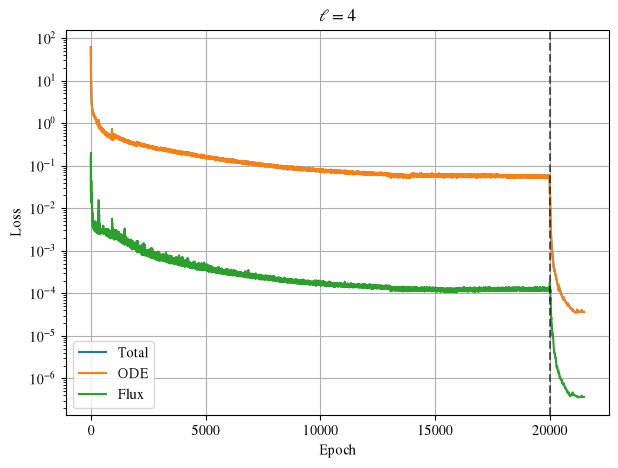

In [12]:
#Loss curves (from loss_history.csv)
L = D["loss"]
n_adam = int((L["stage"] == "Adam").sum())

fig, ax = plt.subplots(figsize = (7, 5))
for col, lab in (("total_loss", "Total"), ("ode_loss", "ODE"), ("flux_loss", "Flux")):
    ax.plot(L["epoch"], L[col], label = lab)
ax.set_yscale("log")
ax.axvline(n_adam, color = "k", ls = "--", alpha = 0.6)
ax.set(xlabel = "Epoch", ylabel = "Loss", title = rf"$\ell = {mode}$")
ax.grid()
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "loss.pdf"), bbox_inches = "tight")
plt.show()


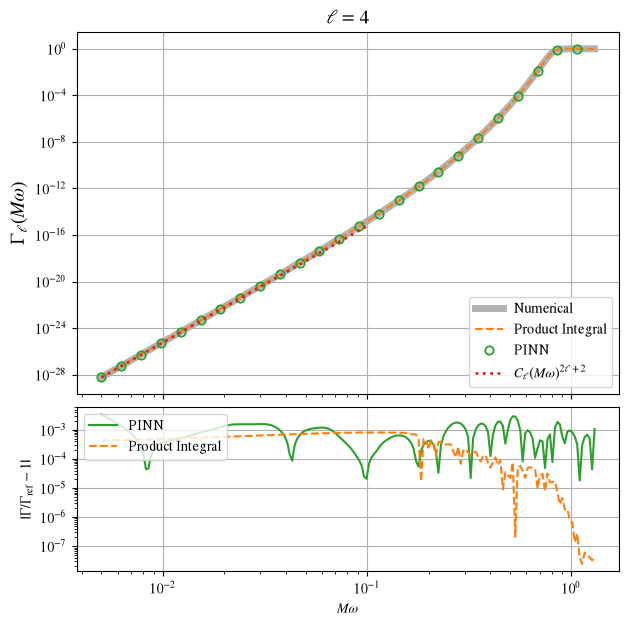

In [13]:
#Two panel GBF comparison (from extraction_report.csv)
R = D["report"]
Mw = R["Momega"].to_numpy()
g_pinn, g_pi, g_ref = R["GBF_PINN_new"].to_numpy(), R["GBF_product_integral"].to_numpy(), R["GBF_reference"].to_numpy()
low = Mw <= 0.1
g_low = P["low_frequency_limit_GBF"](mass, mode, Mw/mass)
step = max(1, len(Mw)//25)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize = (7, 7), sharex = True, gridspec_kw = {"height_ratios": [2.2, 1], "hspace": 0.05})
ax0.loglog(Mw, g_ref, "-", color = "0.7", lw = 5, zorder = 1, label = "Numerical")
ax0.loglog(Mw, g_pi, "--", color = "tab:orange", lw = 1.5, zorder = 2, label = "Product Integral")
ax0.loglog(Mw[::step], g_pinn[::step], "o", mfc = "none", mec = "tab:green", mew = 1.3, ms = 6, zorder = 3, label = "PINN")
ax0.loglog(Mw[low], g_low[low], ":", color = "tab:red", lw = 2, zorder = 4, label = r"$C_\ell (M \omega)^{2 \ell + 2}$")
ax0.set_ylabel(r"$\Gamma_\ell (M \omega)$", fontsize = 14)
ax0.set_title(rf"$\ell = {mode}$", fontsize = 14)
ax0.grid()
ax0.legend(fontsize = 10, loc = "lower right")
ax1.loglog(Mw, np.maximum(np.abs(g_pinn/g_ref - 1), 1e-17), "-", color = "tab:green", lw = 1.5, label = "PINN")
ax1.loglog(Mw, np.maximum(np.abs(g_pi/g_ref - 1), 1e-17), "--", color = "tab:orange", lw = 1.5, label = "Product Integral")
ax1.set(xlabel = r"$M \omega$", ylabel = r"$|\Gamma/\Gamma_{\rm ref} - 1|$")
ax1.grid()
ax1.legend(fontsize = 10, loc = "upper left")
fig.savefig(os.path.join(FIG_DIR, "GBF_comparison.pdf"), bbox_inches = "tight")
plt.show()

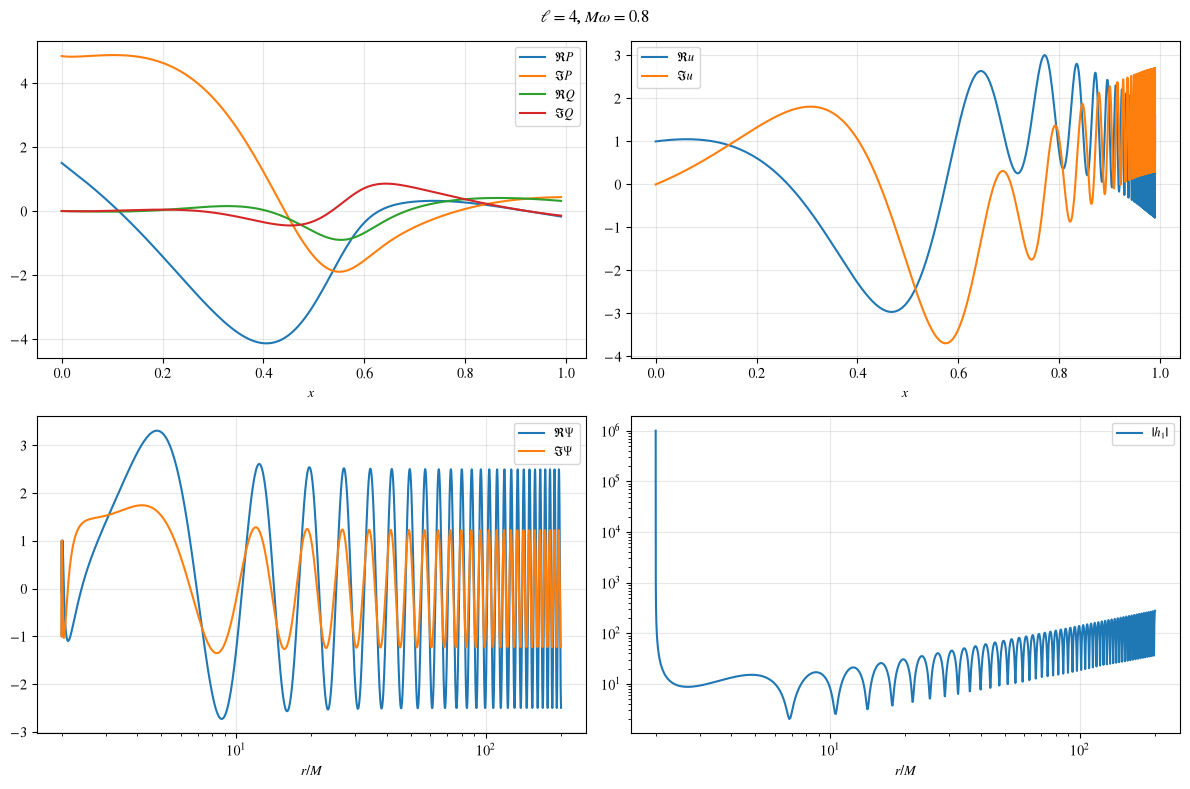

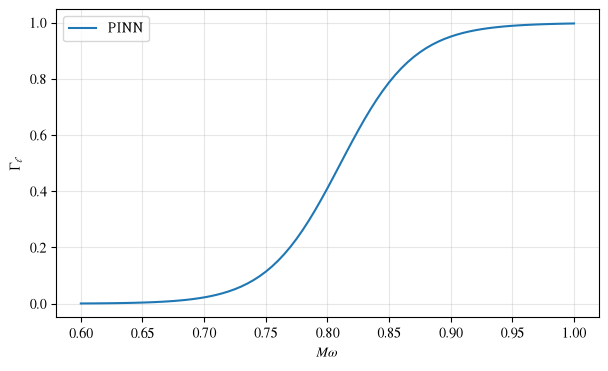

In [14]:
#Wavefunction pipeline at any frequency (uses the network)
Mw_plot = 0.8                     #choose any M*omega inside the training range
omega_plot = Mw_plot/mass
x_grid, r_plot, rstar_plot = P["pipeline_grid"](mass, omega_plot)
x_v, u_re, u_im, P_re, P_im, Q_re, Q_im = P["query_wavefunction"](model, mass, mode, omega_plot, x_grid)
u = u_re + 1j*u_im
Psi = np.exp(-1j*omega_plot*rstar_plot)*u
h1 = r_plot*Psi/(1 - 2*mass/r_plot)

fig, axes = plt.subplots(2, 2, figsize = (12, 8))
axes[0, 0].plot(x_v, P_re, label = r"$\Re P$"); axes[0, 0].plot(x_v, P_im, label = r"$\Im P$")
axes[0, 0].plot(x_v, Q_re, label = r"$\Re Q$"); axes[0, 0].plot(x_v, Q_im, label = r"$\Im Q$")
axes[0, 1].plot(x_v, u.real, label = r"$\Re u$"); axes[0, 1].plot(x_v, u.imag, label = r"$\Im u$")
axes[1, 0].semilogx(r_plot/mass, Psi.real, label = r"$\Re\Psi$"); axes[1, 0].semilogx(r_plot/mass, Psi.imag, label = r"$\Im\Psi$")
axes[1, 1].loglog(r_plot/mass, np.abs(h1), label = r"$|h_1|$")
for ax, xl in zip(axes.flat, (r"$x$", r"$x$", r"$r/M$", r"$r/M$")):
    ax.set_xlabel(xl); ax.grid(alpha = 0.3); ax.legend(fontsize = 9)
fig.suptitle(rf"$\ell = {mode}$, $M\omega = {Mw_plot}$")
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, f"pipeline_Mw{Mw_plot}.pdf"), bbox_inches = "tight")
plt.show()

# %% GBF on a new frequency grid (e.g. denser near the transition), straight from the network
Mw_new = np.linspace(0.6, 1.0, 81)
gbf_new = np.array([P["extraction"](model, x_max, mass, mode, w/mass)[3] for w in Mw_new])
plt.figure(figsize = (7, 4))
plt.plot(Mw_new, gbf_new, label = "PINN")
plt.xlabel(r"$M\omega$"); plt.ylabel(r"$\Gamma_\ell$"); plt.grid(alpha = 0.3); plt.legend()
plt.show()

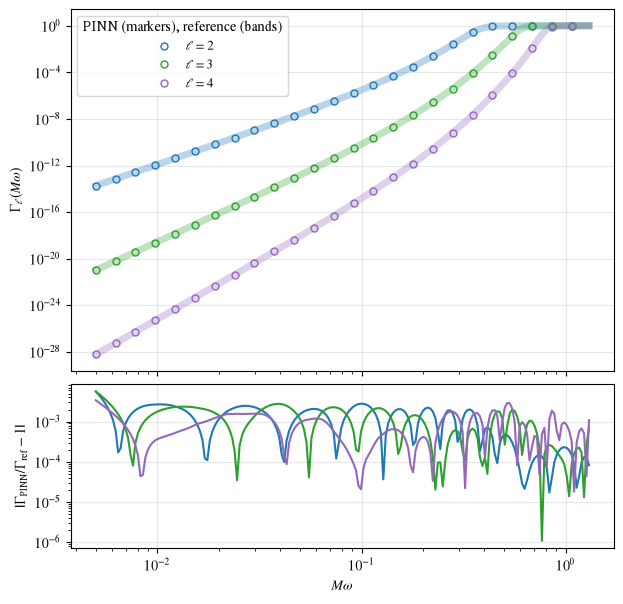

In [15]:
#Combined multi-l figure from several run folders (CSV only; no model needed)
MULTI_DIR = os.path.dirname(RUN_DIR)          #warm-start runs: the folder holding l2/, l3/, l4/
fig, (ax0, ax1) = plt.subplots(2, 1, figsize = (7, 7), sharex = True, gridspec_kw = {"height_ratios": [2.2, 1], "hspace": 0.05})
for run in sorted(glob.glob(os.path.join(MULTI_DIR, "l*")), key = lambda p: int(os.path.basename(p)[1:])):
    l = int(os.path.basename(run)[1:])
    R_l = pd.read_csv(os.path.join(run, "comparisons", "extraction_report.csv"))
    line, = ax0.loglog(R_l["Momega"], R_l["GBF_reference"], "-", lw = 5, alpha = 0.3)
    ax0.loglog(R_l["Momega"][::step], R_l["GBF_PINN_new"][::step], "o", mfc = "none", mec = line.get_color(), ms = 5, label = rf"$\ell = {l}$")
    ax1.loglog(R_l["Momega"], np.maximum(np.abs(R_l["GBF_PINN_new"]/R_l["GBF_reference"] - 1), 1e-17), color = line.get_color())
ax0.set_ylabel(r"$\Gamma_\ell(M\omega)$"); ax0.grid(alpha = 0.3); ax0.legend(title = "PINN (markers), reference (bands)", fontsize = 9)
ax1.set(xlabel = r"$M\omega$", ylabel = r"$|\Gamma_{\rm PINN}/\Gamma_{\rm ref} - 1|$"); ax1.grid(alpha = 0.3)
fig.savefig(os.path.join(MULTI_DIR, "multi_l_GBF_comparison.pdf"), bbox_inches = "tight")
plt.show()